Type 2 Diabetes Risk Prediction. Implement all traditional classfication algorithm .

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

In [ ]:

df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
df.shape

(100000, 9)

In [ ]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [ ]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [ ]:
df["diabetes"].value_counts()

,count
diabetes,
0,91500
1,8500


In [ ]:
df.duplicated().sum()

np.int64(3854)

In [ ]:
from pandas.core.arrays import categorical
numerical_features = df.select_dtypes(exclude = 'object').columns
categorical_features = df.select_dtypes(include= 'object').columns
print("Numerical feature count:", len(numerical_features))
print("Numerical features: ", numerical_features)
print("Categorical feature count:", len(categorical_features))
print("Categorical features: ", categorical_features)

Numerical feature count: 7
Numerical features:  Index(['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level',
       'blood_glucose_level', 'diabetes'],
      dtype='object')
Categorical feature count: 2
Categorical features:  Index(['gender', 'smoking_history'], dtype='object')


In [ ]:
print("Unique values in 'gender column:")
print(df['gender'].unique())
print("Unique values in 'smoking_history' column:")
print(df['smoking_history'].unique())

Unique values in 'gender column:
['Female' 'Male' 'Other']
Unique values in 'smoking_history' column:
['never' 'No Info' 'current' 'former' 'ever' 'not current']


In [ ]:
from sklearn.preprocessing import LabelEncoder
encoders = {}

for feature in categorical_features:
    encoder = LabelEncoder()
    df[feature] = encoder.fit_transform(df[feature])
    encoders[feature] = encoder
    print(df[feature].unique())

[0 1 2]
[4 0 1 3 2 5]


In [ ]:
#classification algorithms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [ ]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (80000, 8)
X_test shape: (20000, 8)
y_train shape: (80000,)
y_test shape: (20000,)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Drop the row containing NaN in the 'diabetes' column
df.dropna(subset=['diabetes'], inplace=True)

# Re-split the cleaned dataset
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Re-scale the clean datasets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# LOGISTIC REGRESSION
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
lr_predictions = lr_model.predict(X_test_scaled)

In [ ]:
logistic_accuracy = accuracy_score(y_test, lr_predictions)
logistic_recall = recall_score(y_test, lr_predictions)
logistic_precision = precision_score(y_test, lr_predictions)
logistic_f1 = f1_score(y_test, lr_predictions)

print("LOGISTIC REGRESSION")
print("Accuracy:", logistic_accuracy)
print("Recall:", logistic_recall)
print("Precision:", logistic_precision)
print("F1 Score:", logistic_f1)

LOGISTIC REGRESSION
Accuracy: 0.95865
Recall: 0.6124121779859485
Precision: 0.8637489677952106
F1 Score: 0.7166837958204865


In [ ]:
print("Classification Report for Logistic Regression:")
print(classification_report(y_test, lr_predictions))

print("Confusion Matrix for Logistic Regression:")
print(confusion_matrix(y_test, lr_predictions))

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     18292
           1       0.86      0.61      0.72      1708

    accuracy                           0.96     20000
   macro avg       0.91      0.80      0.85     20000
weighted avg       0.96      0.96      0.96     20000

Confusion Matrix for Logistic Regression:
[[18127   165]
 [  662  1046]]


In [ ]:
#K NEAREST NEIGHBOUR
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:
knn_pred = knn_model.predict(X_test_scaled)

In [ ]:
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)

print("K NEAREST NEIGHBOUR")
print("Accuracy:", knn_accuracy)
print("Recall:", knn_recall)
print("Precision:", knn_precision)
print("F1 Score:", knn_f1)

K NEAREST NEIGHBOUR
Accuracy: 0.9613
Recall: 0.6217798594847775
Precision: 0.892436974789916
F1 Score: 0.7329192546583851


In [ ]:
print("Classification Report for KNN:")
print(classification_report(y_test, knn_pred))

print("Confusion Matrix for KNN:")
print(confusion_matrix(y_test, knn_pred))

Classification Report for KNN:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18292
           1       0.89      0.62      0.73      1708

    accuracy                           0.96     20000
   macro avg       0.93      0.81      0.86     20000
weighted avg       0.96      0.96      0.96     20000

Confusion Matrix for KNN:
[[18164   128]
 [  646  1062]]


In [ ]:
#DECISION TREE
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
dt_model_pred = dt_model.predict(X_test_scaled)

In [ ]:
dt_accuracy = accuracy_score(y_test, dt_model_pred)
dt_recall = recall_score(y_test, dt_model_pred)
dt_precision = precision_score(y_test, dt_model_pred)
dt_f1 = f1_score(y_test, dt_model_pred)

print("DECISION TREE")
print("Accuracy:", dt_accuracy)
print("Recall:", dt_recall)
print("Precision:", dt_precision)
print("F1 Score:", dt_f1)

DECISION TREE
Accuracy: 0.95235
Recall: 0.7388758782201406
Precision: 0.7133973996608253
F1 Score: 0.725913143514524


In [ ]:
print("Classification Report for Decision Tree:")
print(classification_report(y_test, dt_model_pred))

print("Confusion Matrix for Decision Tree:")
print(confusion_matrix(y_test, dt_model_pred))

Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97     18292
           1       0.71      0.74      0.73      1708

    accuracy                           0.95     20000
   macro avg       0.84      0.86      0.85     20000
weighted avg       0.95      0.95      0.95     20000

Confusion Matrix for Decision Tree:
[[17785   507]
 [  446  1262]]


In [ ]:
#RANDOM FOREST
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
rf_model_pred = rf_model.predict(X_test_scaled)

In [ ]:
rf_accuracy = accuracy_score(y_test, rf_model_pred)
rf_recall = recall_score(y_test, rf_model_pred)
rf_precision = precision_score(y_test, rf_model_pred)
rf_f1 = f1_score(y_test, rf_model_pred)

print("RANDOM FOREST")
print("Accuracy:", rf_accuracy)
print("Recall:", rf_recall)
print("Precision:", rf_precision)
print("F1 Score:", rf_f1)

RANDOM FOREST
Accuracy: 0.97075
Recall: 0.6914519906323185
Precision: 0.9531880548829701
F1 Score: 0.8014930437733289


In [ ]:
print("Classification Report for Random Forest:")
print(classification_report(y_test, rf_model_pred))

print("Confusion Matrix for Random Forest:")
print(confusion_matrix(y_test, rf_model_pred))

Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     18292
           1       0.95      0.69      0.80      1708

    accuracy                           0.97     20000
   macro avg       0.96      0.84      0.89     20000
weighted avg       0.97      0.97      0.97     20000

Confusion Matrix for Random Forest:
[[18234    58]
 [  527  1181]]


In [ ]:

# SUPPORT VEC TOR MACHINE

from sklearn.svm import SVC

svm_model = SVC(
    probability=True,
    random_state=42,
    kernel='rbf'
)

svm_model.fit(X_train_scaled, y_train)

svm_model_pred = svm_model.predict(X_test_scaled)

print("SVM training completed successfully!")


SVM training completed successfully!


In [ ]:
svm_model_pred = svm_model.predict(X_test_scaled)

In [ ]:
svm_accuracy = accuracy_score(y_test, svm_model_pred)
svm_recall = recall_score(y_test, svm_model_pred)
svm_precision = precision_score(y_test, svm_model_pred)
svm_f1 = f1_score(y_test, svm_model_pred)

print("SUPPORT VECTOR MACHINE")
print("Accuracy:", svm_accuracy)
print("Recall:", svm_recall)
print("Precision:", svm_precision)
print("F1 Score:", svm_f1)

SUPPORT VECTOR MACHINE
Accuracy: 0.96235
Recall: 0.5731850117096019
Precision: 0.9760717846460618
F1 Score: 0.7222427148653633


In [ ]:
print("Classification Report for Support Vector Machine:")
print(classification_report(y_test, svm_model_pred))

print("Confusion Matrix for Support Vector Machine:")
print(confusion_matrix(y_test, svm_model_pred))

Classification Report for Support Vector Machine:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     18292
           1       0.98      0.57      0.72      1708

    accuracy                           0.96     20000
   macro avg       0.97      0.79      0.85     20000
weighted avg       0.96      0.96      0.96     20000

Confusion Matrix for Support Vector Machine:
[[18268    24]
 [  729   979]]


In [ ]:
comaprision = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'Support Vector Machine'],
    'Accuracy': [logistic_accuracy, knn_accuracy, dt_accuracy, rf_accuracy, svm_accuracy],
    'Recall': [logistic_recall, knn_recall, dt_recall, rf_recall, svm_recall],
    'F1 Score': [logistic_f1, knn_f1, dt_f1, rf_f1, svm_f1]
})

print(comaprision.round(4))

                    Model  Accuracy  Recall  F1 Score
0     Logistic Regression    0.9586  0.6124    0.7167
1                     KNN    0.9613  0.6218    0.7329
2           Decision Tree    0.9524  0.7389    0.7259
3           Random Forest    0.9708  0.6915    0.8015
4  Support Vector Machine    0.9624  0.5732    0.7222


<Figure size 1200x600 with 0 Axes>

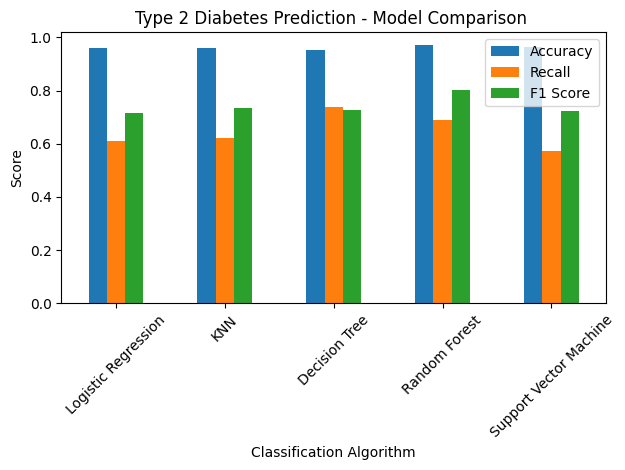

In [ ]:
plt.figure(figsize=(12, 6))
comaprision.set_index("Model")[["Accuracy", "Recall", "F1 Score"]].plot(kind="bar")
plt.title("Type 2 Diabetes Prediction - Model Comparison ")
plt.xlabel("Classification Algorithm")
plt.ylabel("Score")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Support Vector Machine": svm_model

}

accuracy = [
    logistic_accuracy,
    knn_accuracy,
    dt_accuracy,
    rf_accuracy,
    svm_accuracy
]

best_accuracy = max(accuracy)
best_model_name = list(models.keys())[accuracy.index(best_accuracy)]
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best Accuracy:", best_accuracy)
print("Model Object", best_model)

Best Model: Random Forest
Best Accuracy: 0.97075
Model Object RandomForestClassifier(random_state=42)


In [ ]:
#VOTING
from sklearn.ensemble import VotingClassifier
voting_model = VotingClassifier(estimators=[
    ('lr', lr_model),
    ('knn', knn_model),
    ('dt', dt_model),
    ('rf', rf_model),
    ('svm', svm_model)
], voting='soft')

voting_model.fit(X_train_scaled, y_train)

VotingClassifier(estimators=[('lr',
                              LogisticRegression(max_iter=1000,
                                                 random_state=42)),
                             ('knn', KNeighborsClassifier()),
                             ('dt', DecisionTreeClassifier(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svm', SVC(probability=True, random_state=42))],
                 voting='soft')

In [ ]:
voting_pred = voting_model.predict(X_test_scaled)

In [ ]:
voting_accuracy = accuracy_score(y_test, voting_pred)
voting_recall = recall_score(y_test, voting_pred)
voting_precision = precision_score(y_test, voting_pred)
voting_f1 = f1_score(y_test, voting_pred)

print("VOTING")
print("Accuracy:", voting_accuracy)
print("Recall:", voting_recall)
print("Precision:", voting_precision)
print("F1 Score:", voting_f1)

VOTING
Accuracy: 0.9702
Recall: 0.6809133489461359
Precision: 0.9579901153212521
F1 Score: 0.7960301163586585


In [ ]:
import joblib
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(encoders, 'encoders.pkl')
#

['encoders.pkl']